# Perhitungan Volume Kedua Lambung Kapal

**Nama:** Faishal  
**NPM:** 25083010024  
**Kelas:** A083  
**Mata Kuliah:** Analisis Numerik

Pada tugas ini saya akan menghitung volume kedua lambung kapal
menggunakan metode numerik. Metode yang digunakan adalah:

1. Metode Trapesium
2. Metode Simpson 1/3

Bagian **reserve buoyancy tidak ikut dihitung**, sesuai dengan ketentuan
pada soal.

Untuk mempermudah perhitungan, penampang kapal dianggap berbentuk
persegi panjang.

## 1. Konsep Perhitungan

Coba kita lihat dulu bagaimana volume kapal dihitung.

Kapal dibagi menjadi beberapa titik sepanjang arah memanjang.
Jarak antar titik adalah **10 cm**.

Pada setiap titik kita menentukan:

- lebar lambung kapal ($b_i$)
- tinggi lambung kapal ($t_i$)

Karena penampang dianggap persegi panjang, luas penampang pada setiap
titik dapat dihitung dengan:

$$
A_i = b_i \times t_i
$$

Setelah semua luas penampang diperoleh, luas tersebut diintegralkan
secara numerik sepanjang kapal untuk mendapatkan volumenya.

Karena terdapat **dua lambung kapal**, hasil volume satu lambung
nantinya dikalikan 2.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Memasukkan Data

Sekarang kita masukkan data hasil pembacaan dari gambar.

Jarak antar titik sepanjang kapal adalah **10 cm**.

Reserve buoyancy pada bagian ujung kapal tidak dimasukkan dalam
perhitungan volume.

Data berikut merupakan data untuk bagian lambung yang dihitung.

In [3]:
# Posisi titik sepanjang kapal (cm)
x = np.arange(20, 181, 10)

# Lebar lambung pada setiap titik (cm)
lebar = np.array([
    15.8, 18.8, 19.9, 20.6, 20.8, 20.8, 20.8,
    20.8, 20.8, 21.0, 20.8, 20.6, 20.6, 19.7,
    18.1, 15.8, 12.9
])

# Tinggi lambung pada setiap titik (cm)
tinggi = np.array([
    17.4, 21.0, 24.4, 24.4, 24.4, 24.4, 24.4,
    24.4, 24.4, 24.4, 24.4, 24.4, 24.4, 24.4,
    24.4, 24.4, 24.2
])

# Jarak antar titik
h = 10

## 3. Melihat Data

Coba kita tampilkan data dalam bentuk tabel supaya lebih mudah
diperiksa sebelum masuk ke perhitungan.

In [4]:
data = pd.DataFrame({
    "Titik": np.arange(len(x)),
    "Posisi x (cm)": x,
    "Lebar (cm)": lebar,
    "Tinggi (cm)": tinggi
})

data

,Titik,Posisi x (cm),Lebar (cm),Tinggi (cm)
0,0,20,15.8,17.4
1,1,30,18.8,21.0
2,2,40,19.9,24.4
3,3,50,20.6,24.4
4,4,60,20.8,24.4
5,5,70,20.8,24.4
6,6,80,20.8,24.4
7,7,90,20.8,24.4
8,8,100,20.8,24.4
9,9,110,21.0,24.4


Dari tabel di atas, setiap titik memiliki posisi yang berjarak
10 cm dari titik sebelumnya.

Selanjutnya kita hitung luas penampang pada masing-masing titik.

Karena bentuk penampang dianggap persegi panjang:

$$
A_i = b_i \times t_i
$$

In [5]:
# Menghitung luas penampang
luas = lebar * tinggi

# Menambahkan luas ke tabel
data["Luas Penampang (cm²)"] = luas

data

,Titik,Posisi x (cm),Lebar (cm),Tinggi (cm),Luas Penampang (cm²)
0,0,20,15.8,17.4,274.92
1,1,30,18.8,21.0,394.80
2,2,40,19.9,24.4,485.56
3,3,50,20.6,24.4,502.64
4,4,60,20.8,24.4,507.52
5,5,70,20.8,24.4,507.52
6,6,80,20.8,24.4,507.52
7,7,90,20.8,24.4,507.52
8,8,100,20.8,24.4,507.52
9,9,110,21.0,24.4,512.40


### Bagaimana hasilnya?

Sekarang setiap titik sudah memiliki luas penampang dalam satuan cm².

Misalnya, jika pada suatu titik lebar lambung adalah 15,8 cm dan
tingginya 17,4 cm, maka:

$$
A = 15,8 \times 17,4
$$

Hasilnya sekitar 274,92 cm².

Setelah semua luas diketahui, kita bisa menghitung volume dengan
metode numerik.

## 4. Menghitung Volume dengan Metode Trapesium

Metode pertama yang digunakan adalah metode Trapesium.

Rumusnya:

$$
V =
h
\left[
\frac{A_0 + A_n}{2}
+
\sum_{i=1}^{n-1} A_i
\right]
$$

Pada data ini jarak antar titik adalah:

$$
h = 10 \text{ cm}
$$

Jadi kita menggunakan jarak 10 cm untuk melakukan pendekatan luas
di bawah kurva luas penampang terhadap panjang kapal.

In [7]:
# Metode Trapesium
volume_trapesium_1 = h * (
    (luas[0] + luas[-1]) / 2
    + np.sum(luas[1:-1])
)

print(f"Volume 1 lambung = {volume_trapesium_1:,.2f} cm³")

Volume 1 lambung = 75,471.90 cm³


Karena kapal memiliki **dua lambung**, maka volume total adalah:

$$
V_{total} = 2 \times V_{1\ lambung}
$$

In [8]:
# Volume dua lambung
volume_trapesium_2 = 2 * volume_trapesium_1

# Konversi ke liter
volume_trapesium_liter = volume_trapesium_2 / 1000

print(f"Volume 2 lambung = {volume_trapesium_2:,.2f} cm³")
print(f"Volume 2 lambung = {volume_trapesium_liter:,.2f} liter")

Volume 2 lambung = 150,943.80 cm³
Volume 2 lambung = 150.94 liter


## 5. Menghitung Volume dengan Metode Simpson 1/3

Sekarang kita coba metode kedua, yaitu Simpson 1/3.

Metode Simpson 1/3 membutuhkan jumlah interval yang genap.

Pada data kita terdapat:

$$
n = 16
$$

interval, sehingga metode Simpson 1/3 dapat digunakan.

Rumusnya:

$$
V =
\frac{h}{3}
\left[
A_0 + A_n
+ 4(A_1+A_3+\cdots+A_{n-1})
+ 2(A_2+A_4+\cdots+A_{n-2})
\right]
$$

Di sini:

$$
h = 10 \text{ cm}
$$

In [9]:
# Metode Simpson 1/3

volume_simpson_1 = (h / 3) * (
    luas[0]
    + luas[-1]
    + 4 * np.sum(luas[1:-1:2])
    + 2 * np.sum(luas[2:-1:2])
)

print(f"Volume 1 lambung = {volume_simpson_1:,.2f} cm³")

Volume 1 lambung = 75,606.07 cm³


In [10]:
# Volume dua lambung
volume_simpson_2 = 2 * volume_simpson_1

# Konversi ke liter
volume_simpson_liter = volume_simpson_2 / 1000

print(f"Volume 2 lambung = {volume_simpson_2:,.2f} cm³")
print(f"Volume 2 lambung = {volume_simpson_liter:,.2f} liter")


Volume 2 lambung = 151,212.13 cm³
Volume 2 lambung = 151.21 liter


## 6. Perbandingan Kedua Metode

Nah, sekarang kita sudah mendapatkan hasil dari kedua metode.

Mari kita bandingkan supaya bisa melihat apakah hasilnya jauh berbeda
atau tidak.

In [11]:
# Membuat tabel perbandingan
hasil = pd.DataFrame({
    "Metode": [
        "Trapesium",
        "Simpson 1/3"
    ],
    "1 Lambung (cm³)": [
        volume_trapesium_1,
        volume_simpson_1
    ],
    "2 Lambung (cm³)": [
        volume_trapesium_2,
        volume_simpson_2
    ],
    "2 Lambung (Liter)": [
        volume_trapesium_liter,
        volume_simpson_liter
    ]
})

hasil

,Metode,1 Lambung (cm³),2 Lambung (cm³),2 Lambung (Liter)
0,Trapesium,75471.900000,150943.800000,150.943800
1,Simpson 1/3,75606.066667,151212.133333,151.212133


### Bagaimana hasilnya?

Ternyata hasil dari metode Trapesium dan Simpson 1/3 cukup dekat.

Perbedaannya terjadi karena kedua metode menggunakan pendekatan
numerik yang berbeda dalam menghitung luas di bawah kurva.

Untuk dua lambung:

- Trapesium menghasilkan sekitar **150.943,80 cm³**
- Simpson 1/3 menghasilkan sekitar **151.212,13 cm³**

Selisihnya relatif kecil, sehingga kedua metode memberikan hasil
yang hampir sama.

## 7. Visualisasi Luas Penampang

Sebelum menghitung volume, kita juga bisa melihat bagaimana luas
penampang berubah sepanjang kapal.

Dari grafik ini kita dapat melihat bagian tengah kapal memiliki luas
penampang yang lebih besar, sedangkan bagian ujung semakin mengecil.
Bagian reserve buoyancy tidak dimasukkan ke dalam data perhitungan.

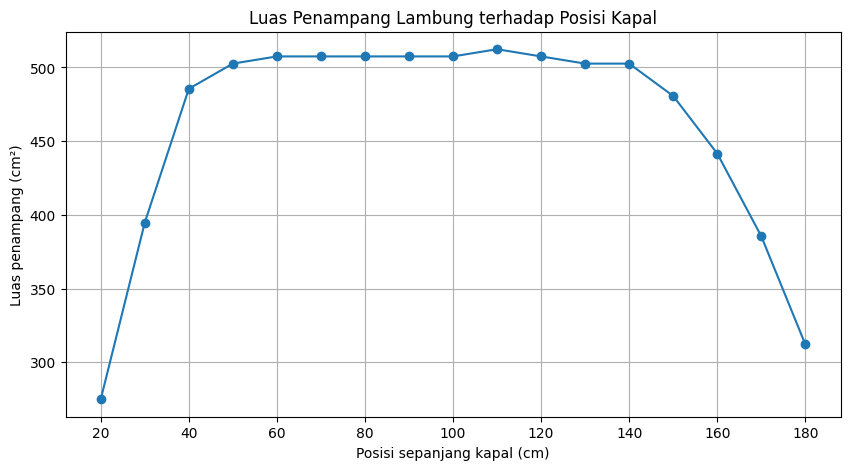

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(x, luas, marker='o')

plt.xlabel("Posisi sepanjang kapal (cm)")
plt.ylabel("Luas penampang (cm²)")
plt.title("Luas Penampang Lambung terhadap Posisi Kapal")
plt.grid(True)

plt.show()

## 8. Kesimpulan

Setelah dilakukan perhitungan menggunakan metode numerik, diperoleh
volume kedua lambung kapal sekitar:

- **150.943,80 cm³** menggunakan metode Trapesium
- **151.212,13 cm³** menggunakan metode Simpson 1/3

Jika dikonversikan ke liter, hasilnya sekitar:

- **150,94 liter** dengan metode Trapesium
- **151,21 liter** dengan metode Simpson 1/3

Hasil kedua metode tidak berbeda jauh. Hal ini menunjukkan bahwa
pendekatan numerik yang digunakan memberikan hasil volume yang relatif
konsisten.

Perhitungan ini hanya menghitung bagian lambung kapal dan **tidak
memasukkan reserve buoyancy**, sesuai dengan ketentuan pada soal.